# Phase 1 verified model evaluation

All numerical outputs below are loaded from independently scored forecast rows. No metric or geographic conclusion is entered manually.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'data/metadata').exists(): ROOT=ROOT.parent
META=ROOT/'data/metadata'
results=json.loads((META/'person_e_results.json').read_text())
metrics=pd.read_csv(META/'phase1_metrics.csv')
display(results['metadata'])

{'generated_at_utc': '2026-10-21T09:22:39.927880+00:00',
 'source': 'independent aligned prediction-row evaluation',
 'packages': {'numpy': '1.26.4',
  'pandas': '2.2.2',
  'scikit-learn': '1.8.0',
  'xgboost': '3.4.1',
  'pyarrow': '19.0.1',
  'tables': '3.9.2',
  'matplotlib': '3.8.4'},
 'speed_units': 'source units; physical units unverified',
 'timezone': 'stored clock; timezone unverified',
 'peak_definition': 'weekday origin hours [07,10) and [16,19)',
 'mape_denominator_floor': 1e-05,
 'congestion_proxy': 'speed < 0.6 * sensor training 85th percentile',
 'spatial_grouping': 'coordinate regions; no verified freeway IDs or direction',
 'bootstrap': '2000 paired circular moving-block resamples of two stored days, seed 42',
 'inference_scope': 'frozen models; no test-based tuning during completion'}

## Shared test benchmark

Every model uses identical valid positive targets and forecast origins. RF and plain XGBoost use 32 features; the historical-average extension uses 36.

,horizon,model,n,mae,rmse,mape
100,5min,persistence,1245052,2.813833,4.626648,6.488311
105,5min,historical_average,1245052,4.188357,7.854829,13.041992
110,5min,random_forest_32,1245052,2.452128,4.155706,6.024745
115,5min,xgboost_32,1245052,2.361780,4.150555,5.758879
120,5min,xgboost_ha,1245052,2.312382,4.065311,5.662481
125,15min,persistence,1245040,3.498912,6.418078,8.611081
130,15min,historical_average,1245040,4.188285,7.854840,13.041876
135,15min,random_forest_32,1245040,3.166828,5.763304,8.558906
140,15min,xgboost_32,1245040,2.969514,5.805916,7.921868
145,15min,xgboost_ha,1245040,2.843682,5.540210,7.628791


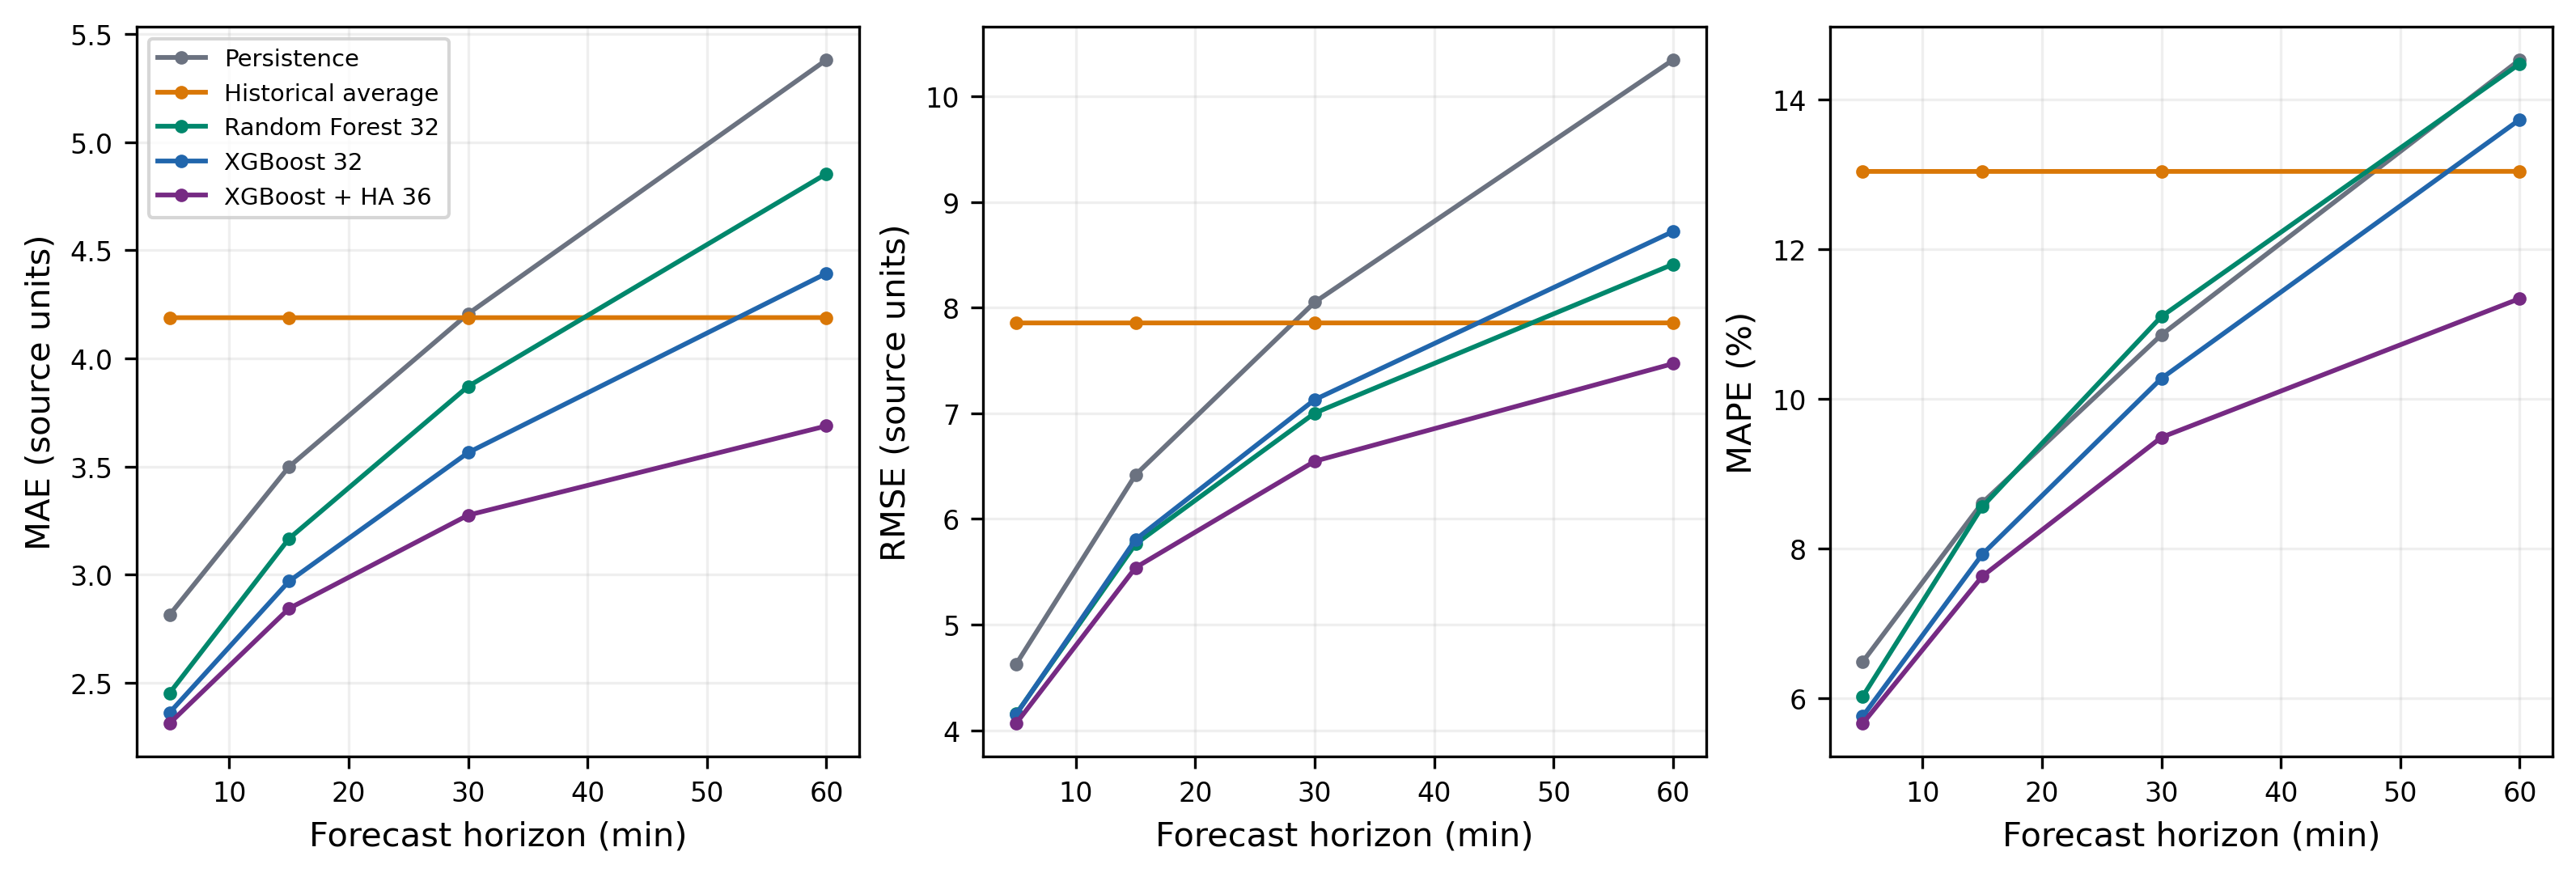

In [2]:
headline=metrics[(metrics.split=='test') & (metrics.period=='all')]
display(headline[['horizon','model','n','mae','rmse','mape']])
assert headline.groupby('horizon').n.nunique().eq(1).all()
display(Image(filename=str(ROOT/'figures/person_e_horizon_metrics_comparison.png')))

## Temporal slices include Random Forest

Morning and evening groups use weekday origin times on the stored clock. The timezone remains unverified.

,model,period,n,mae,rmse,mape
125,persistence,all,1245040,3.498912,6.418078,8.611081
126,persistence,peak,250050,4.619306,8.309508,14.268116
127,persistence,off_peak,994990,3.217347,5.847325,7.189416
128,persistence,morning_peak,121183,4.052798,7.626751,11.851793
129,persistence,evening_peak,128867,5.152034,8.903917,16.540361
130,historical_average,all,1245040,4.188285,7.854840,13.041876
131,historical_average,peak,250050,6.624777,10.766366,24.708992
132,historical_average,off_peak,994990,3.575973,6.933507,10.109824
133,historical_average,morning_peak,121183,5.807104,9.805505,17.850472
134,historical_average,evening_peak,128867,7.393694,11.597530,31.158556


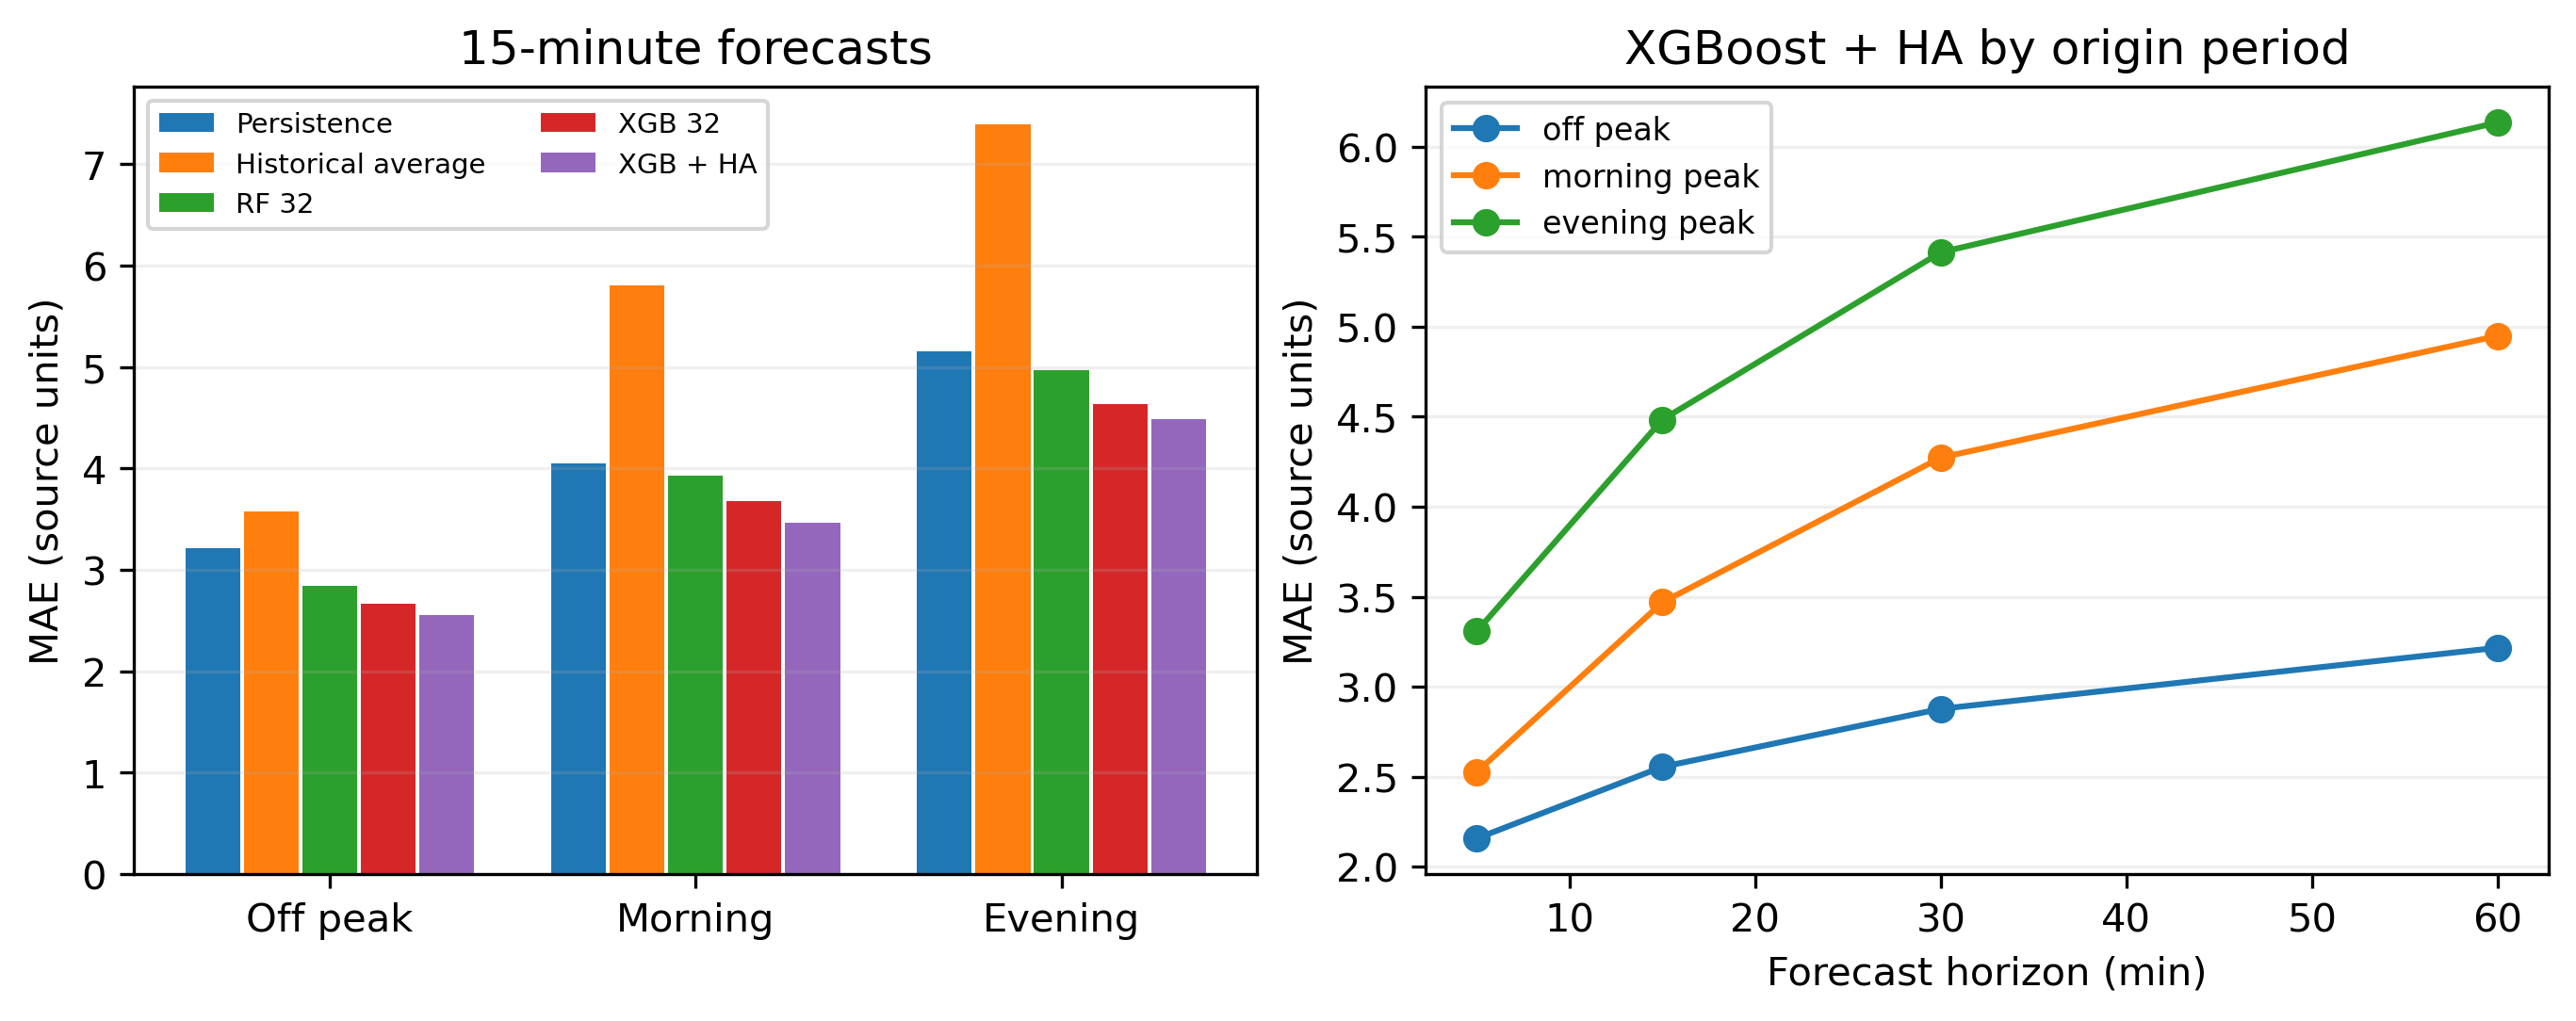

In [3]:
display(metrics[(metrics.split=='test') & (metrics.horizon=='15min')][['model','period','n','mae','rmse','mape']])
display(Image(filename=str(ROOT/'figures/person_e_peak_vs_offpeak_analysis.png')))

## Actual forecast errors on the sensor map

Colors compare observed speed, predicted speed and MAE on identical test targets. The maps do not infer verified freeway membership or traffic direction.

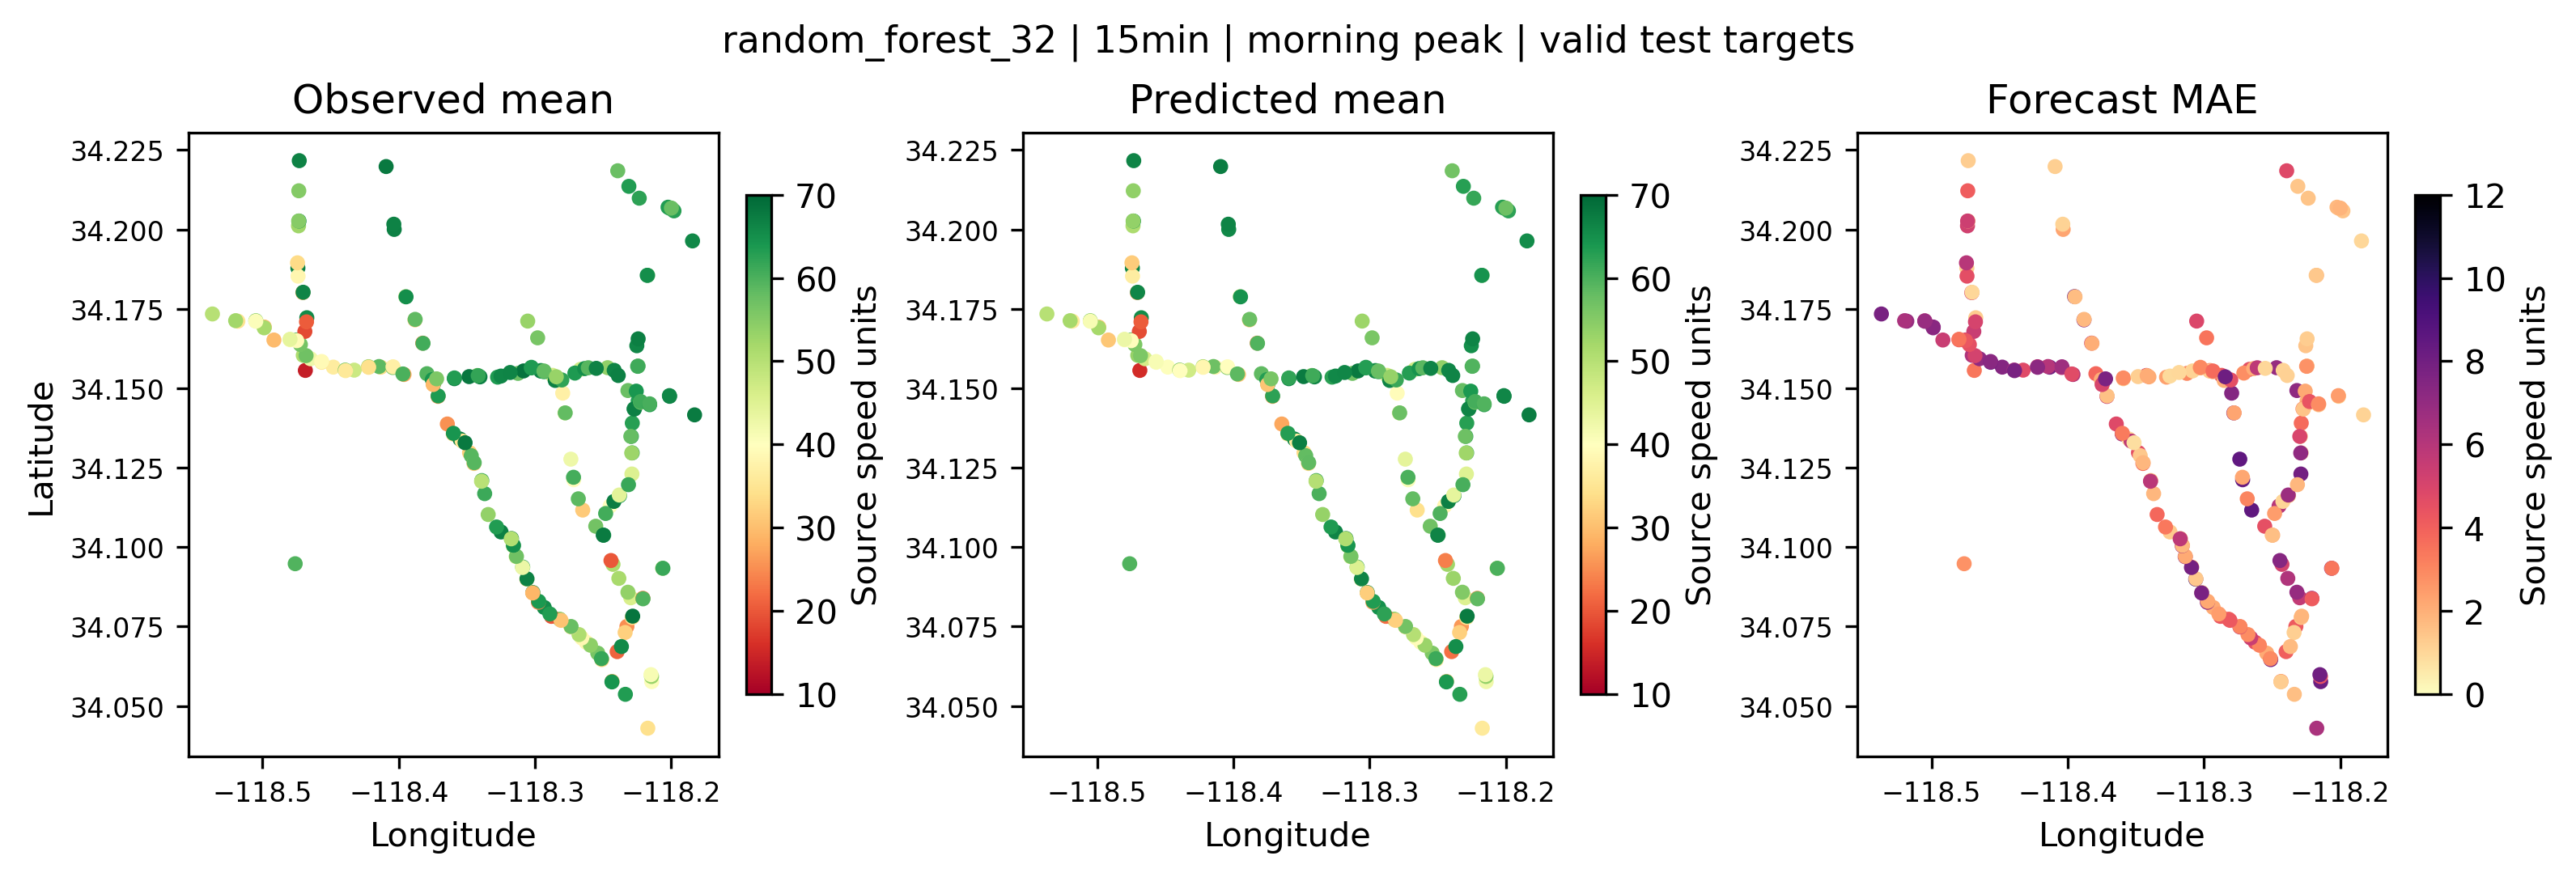

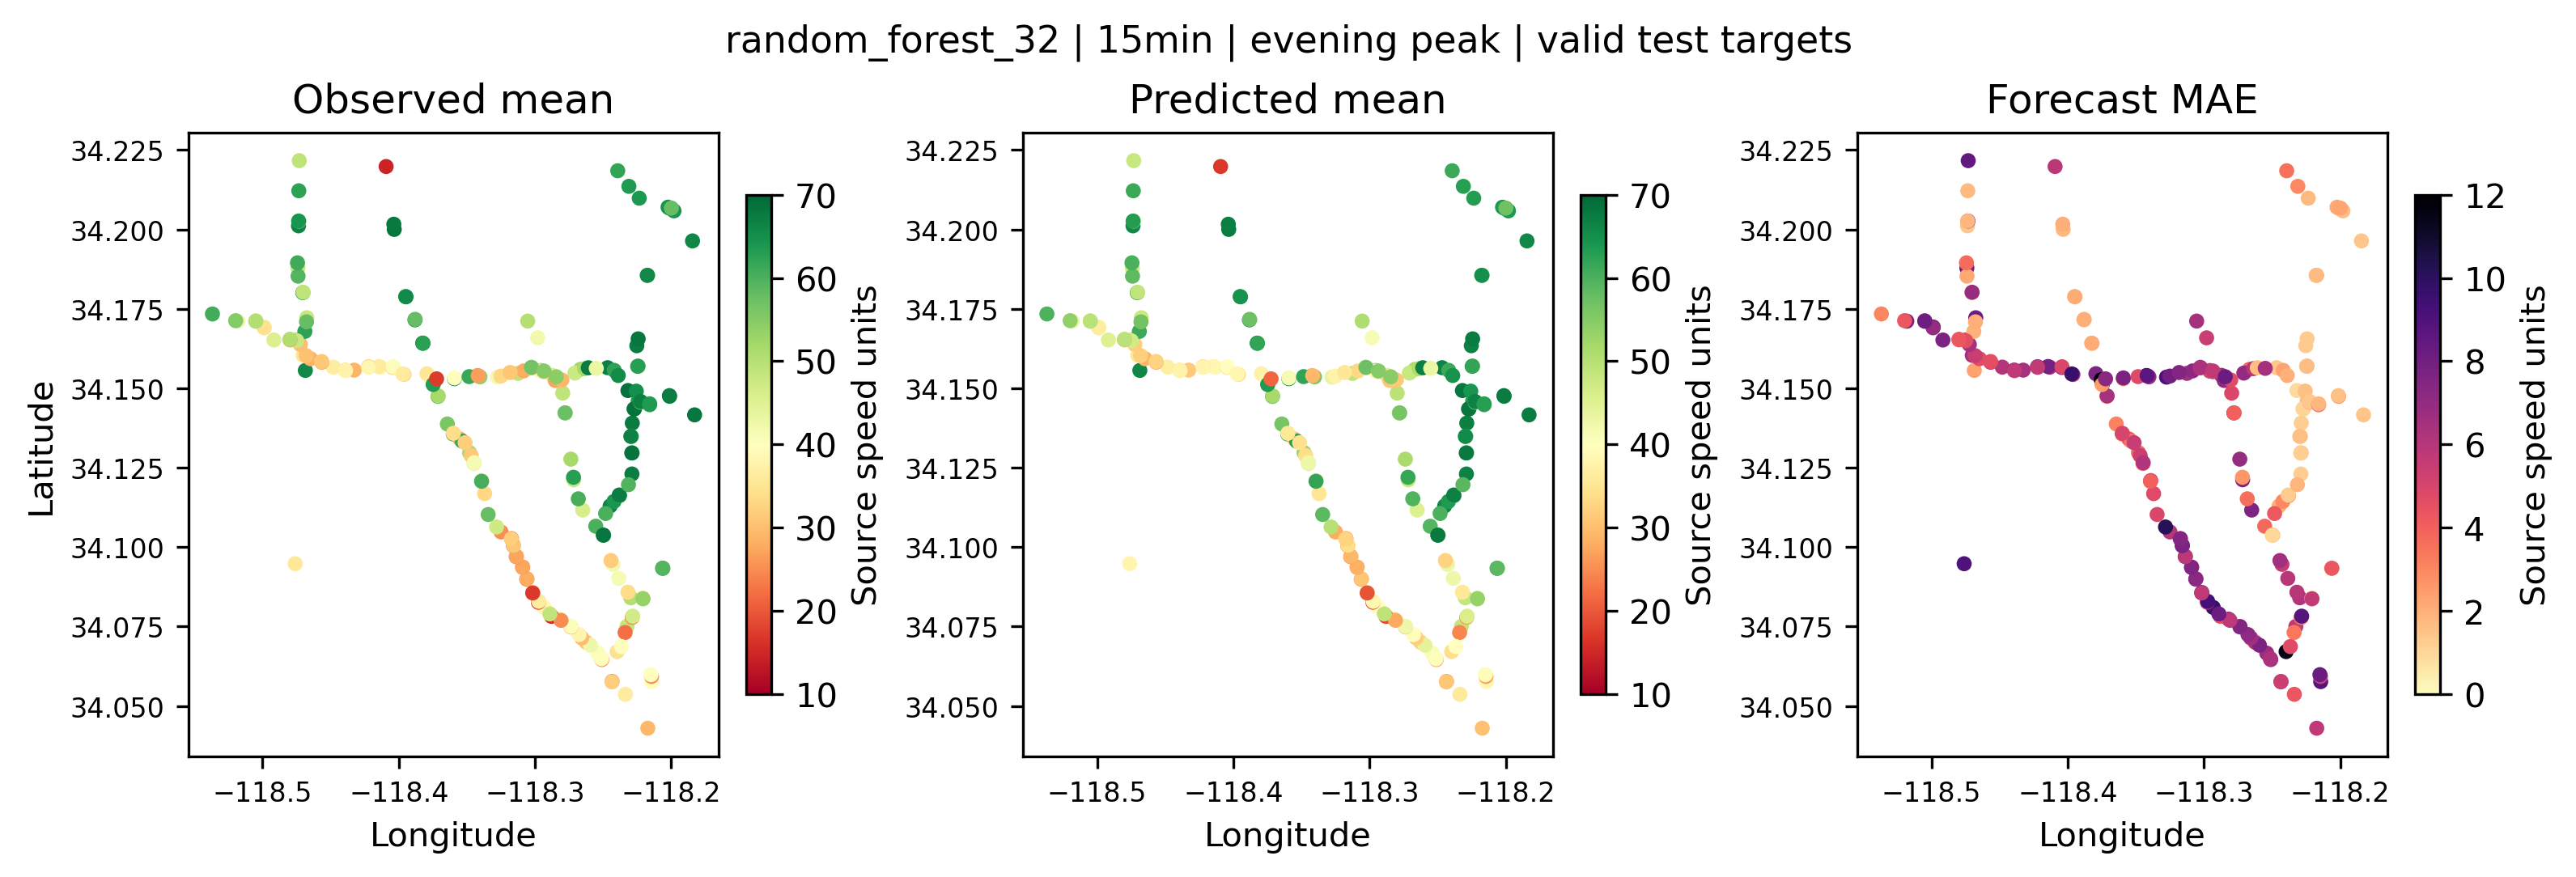

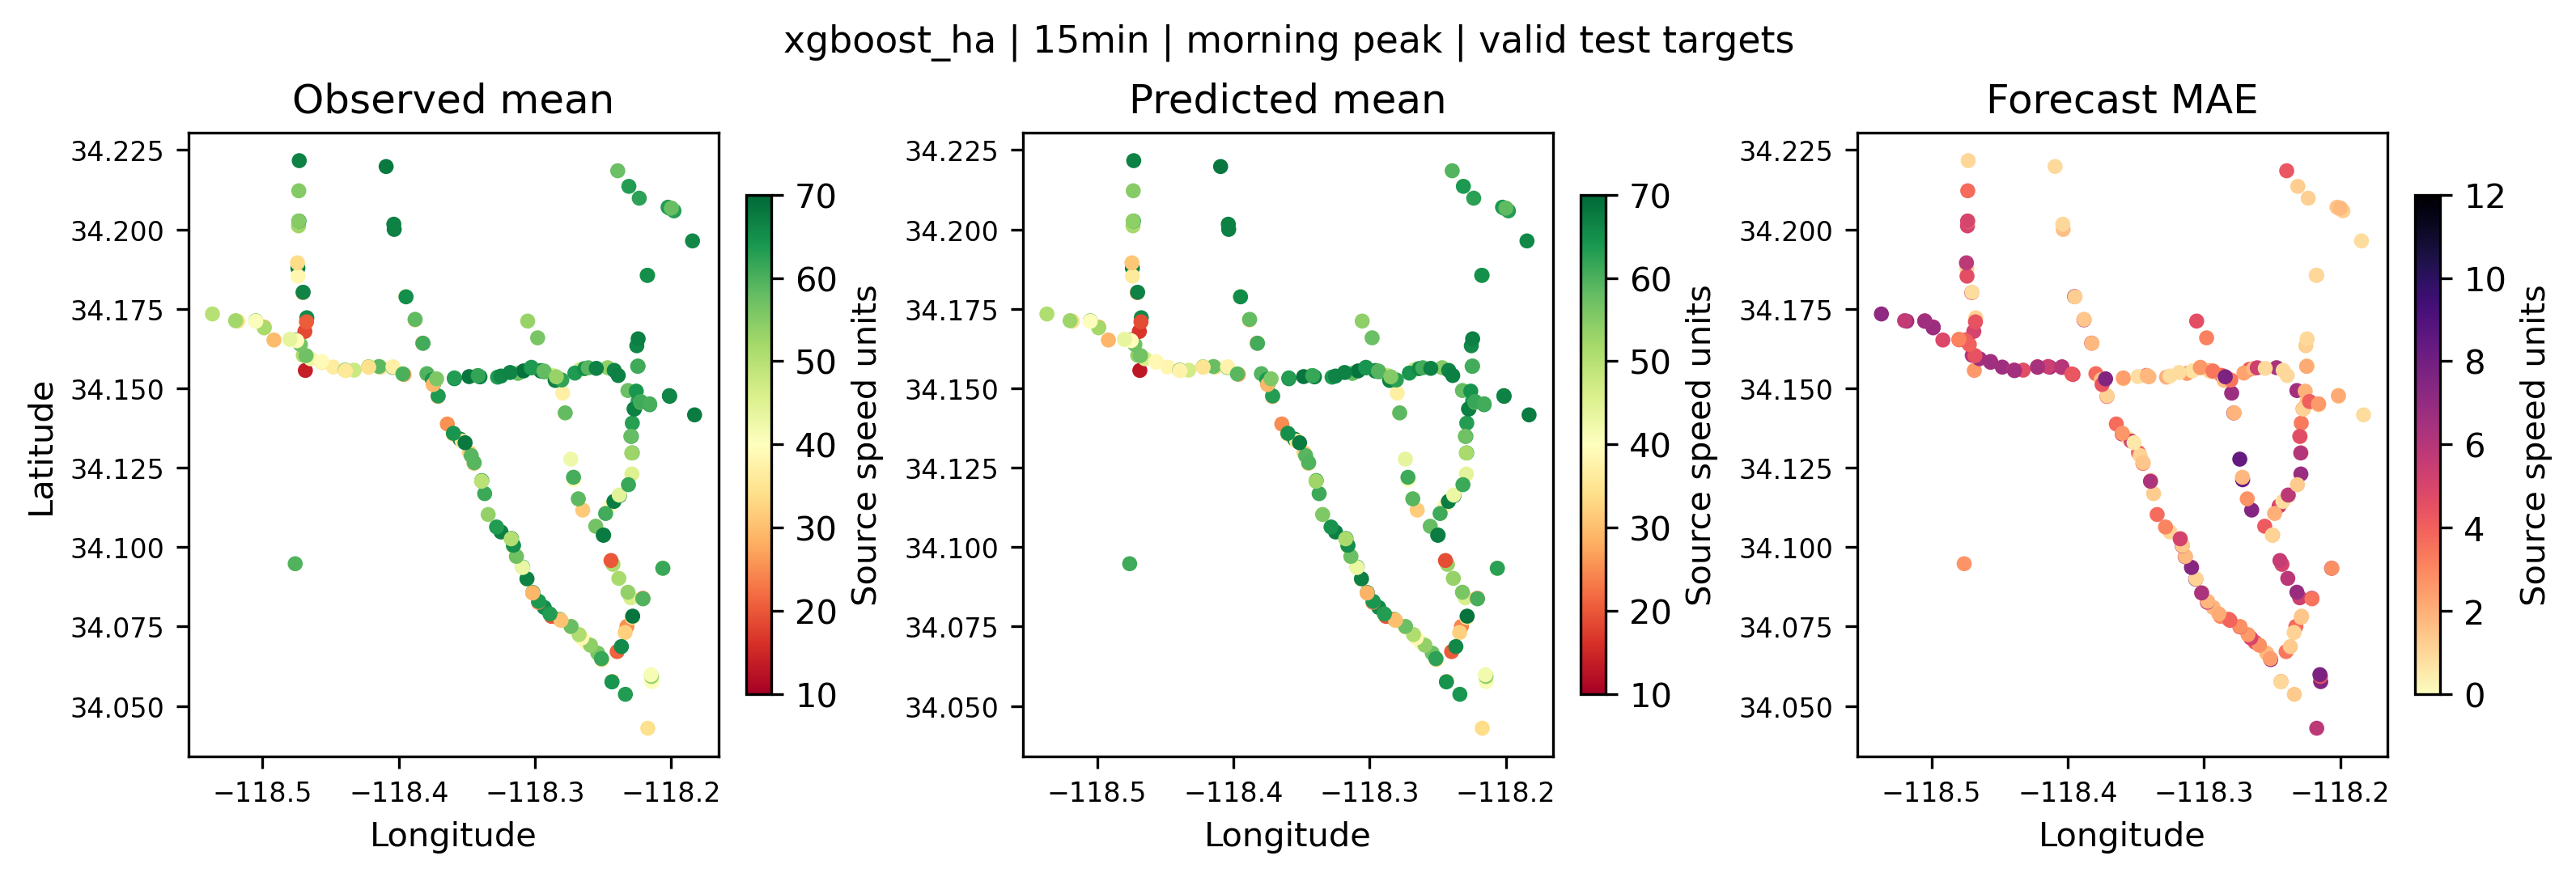

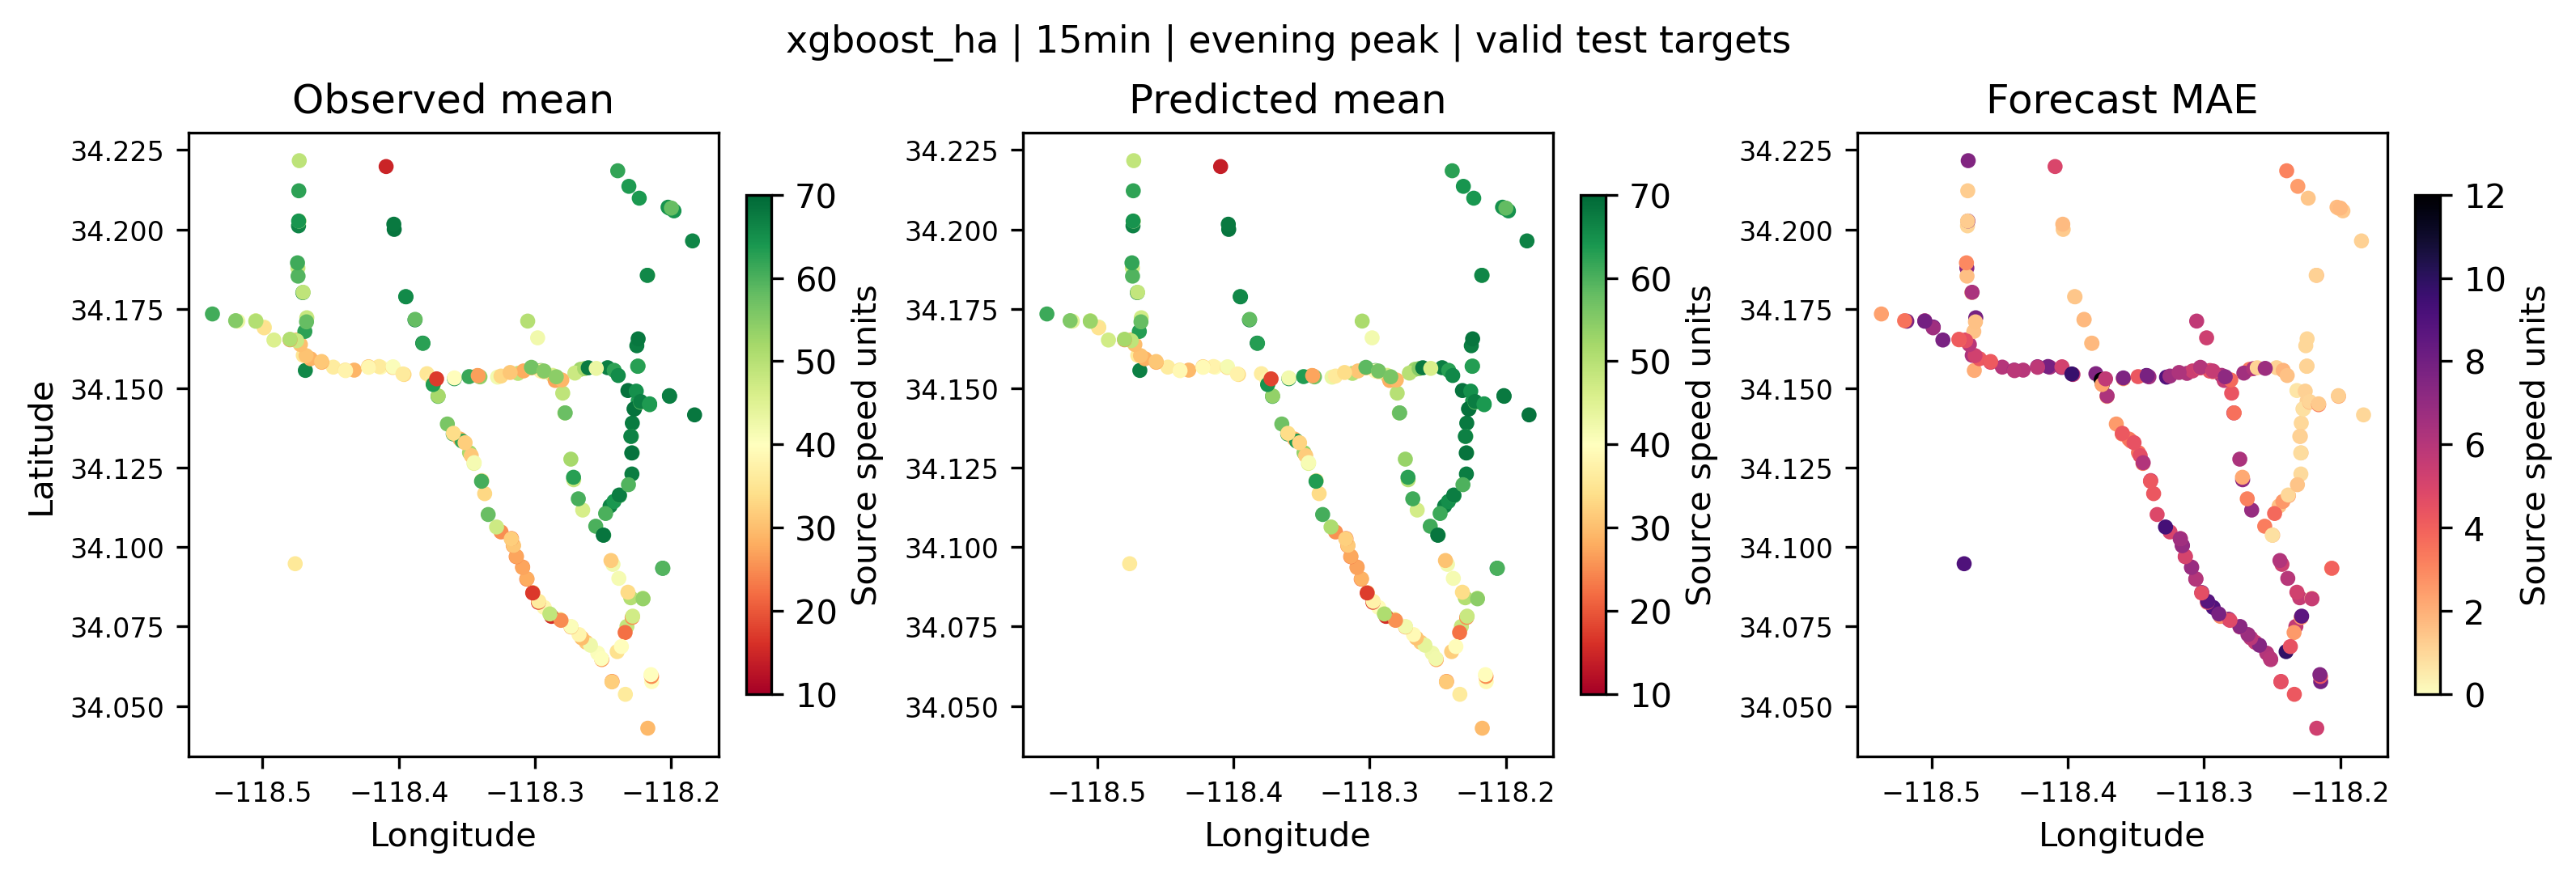

In [4]:
for model in ['random_forest_32','xgboost_ha']:
    for period in ['morning_peak','evening_peak']:
        display(Image(filename=str(ROOT/f'figures/person_e_forecast_map_{model}_{period}.png')))

## Predicted and observed congestion frequency

Congestion is an operational proxy: speed below 60% of the sensor training 85th percentile. The threshold is fitted on train only.

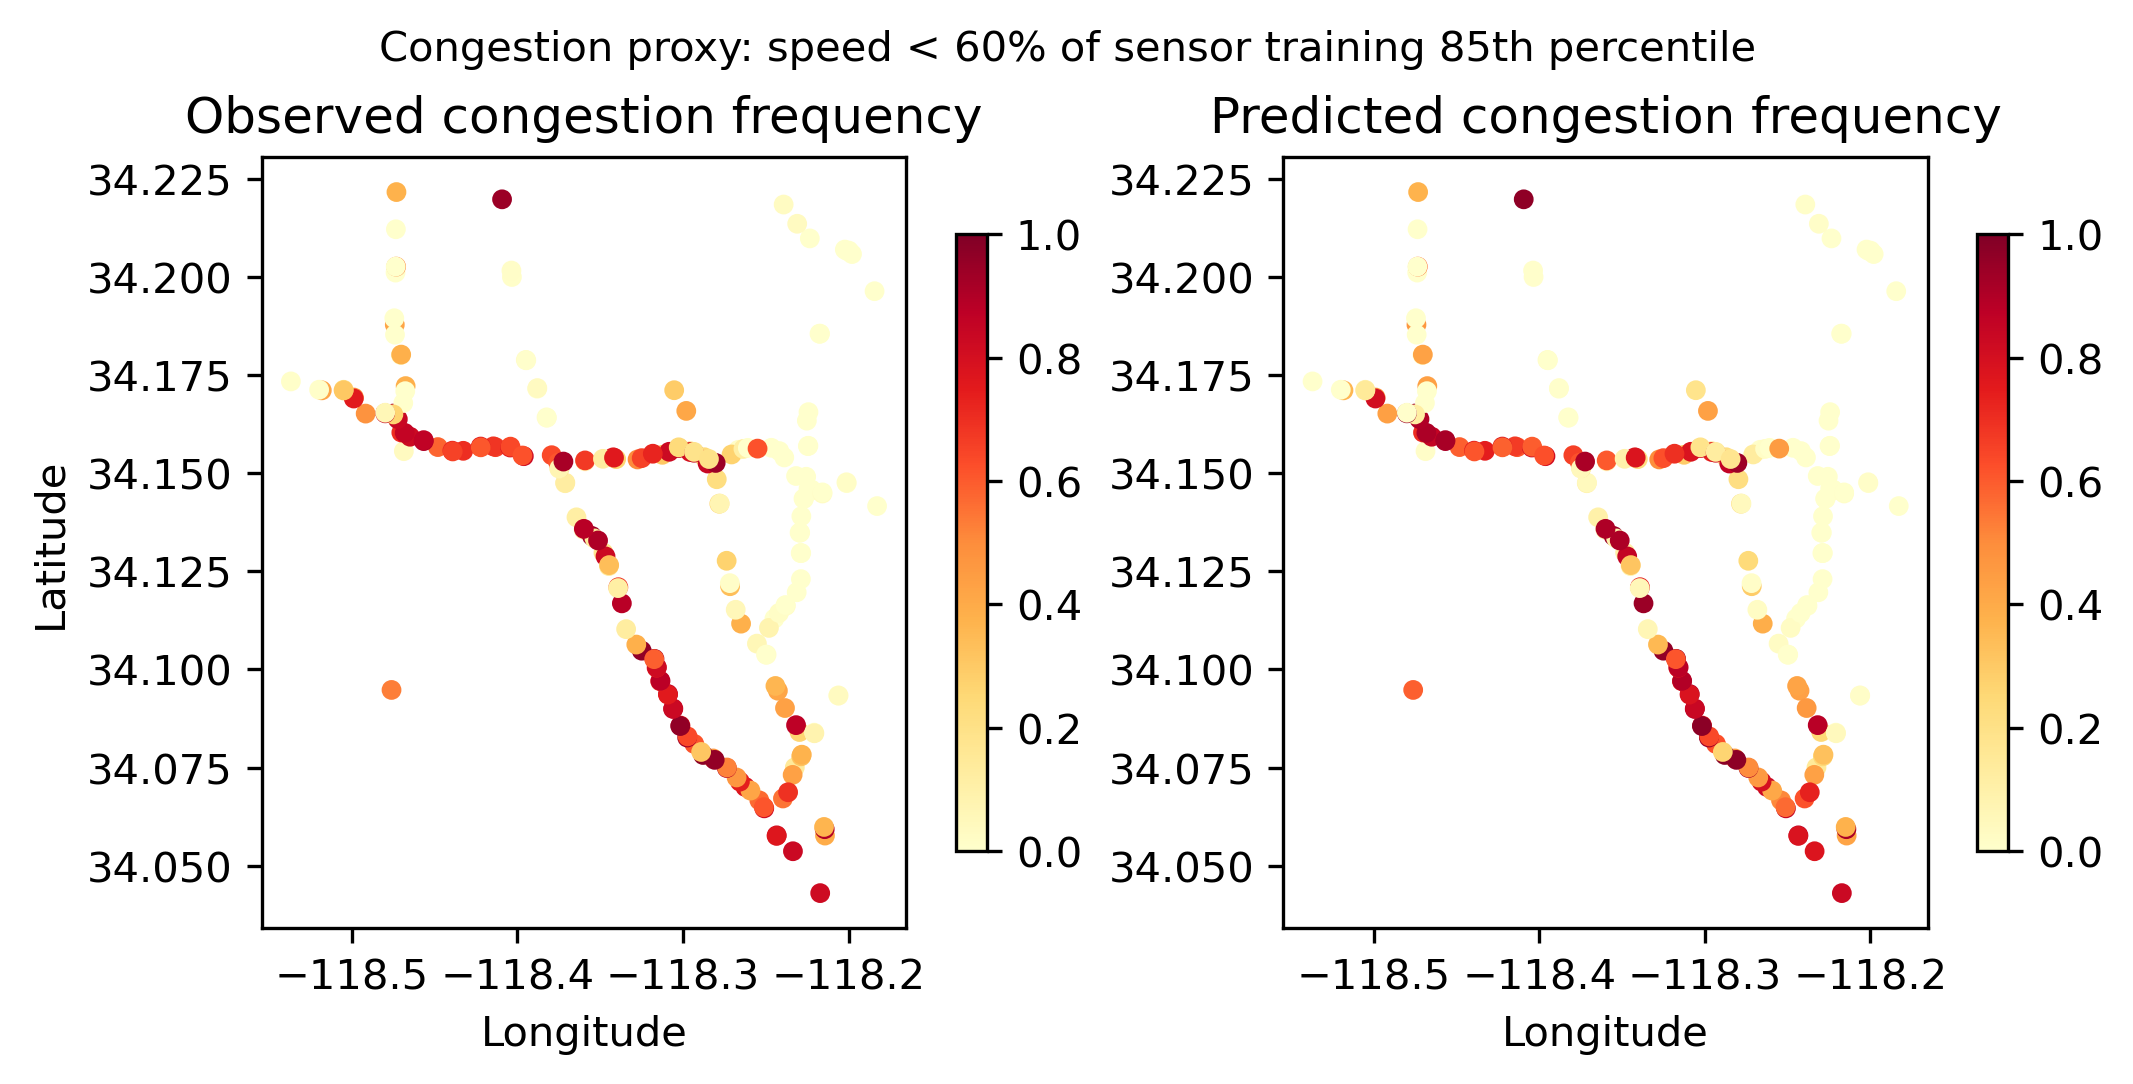

,region,sensor_count,training_reference_speed,grouping,peak_time_basis,morning_valid_targets,mean_morning_speed,morning_reference_speed,morning_speed_drop_pct,evening_valid_targets,mean_evening_speed,evening_reference_speed,evening_speed_drop_pct
0,Central western,9,65.383818,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,5436,43.617341,65.383818,33.290312,5721,32.355484,65.371396,50.505135
1,Southeastern,4,64.236111,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,2254,43.125680,64.155378,32.779322,2355,32.119096,64.172328,49.948681
2,Central eastern,17,60.244865,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,9894,46.588937,60.409052,22.877557,10339,37.261620,60.482977,38.393211
3,North central,63,66.368928,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,37645,55.730662,66.381428,16.044797,39412,42.178298,66.336773,36.417923
4,Western,37,64.888728,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,21490,45.528603,64.866146,29.811457,22368,44.841644,64.843005,30.845827
5,Remaining locations,64,66.616350,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,37461,55.659160,66.730371,16.590963,40554,54.825362,66.723165,17.831592
6,Northern,13,66.061355,coordinate proxy; freeway membership unverified,weekday raw observation timestamp on stored clock,7570,63.370908,66.054120,4.062143,8024,59.843713,66.079736,9.437118


In [5]:
display(Image(filename=str(ROOT/'figures/person_e_predicted_vs_actual_congestion.png')))
display(pd.read_csv(META/'corridor_performance.csv'))

## Per-sensor and geographic error evidence

Rankings below are forecast MAE rather than speed volatility. Regions are reproducible coordinate bins. Weighted error sums and valid counts produce region scores.

In [6]:
ranking=pd.read_csv(META/'sensor_error_rankings.csv')
display(ranking[(ranking.horizon=='15min')&(ranking.model=='xgboost_ha')].head(10)[['sensor_id','region','n','mae','rmse','actual_mean','predicted_mean']])
region=pd.read_csv(META/'region_forecast_metrics.csv')
display(region[(region.split=='test')&(region.horizon=='15min')&(region.model=='xgboost_ha')&(region.period=='all')])

,sensor_id,region,n,mae,rmse,actual_mean,predicted_mean
828,716960,Remaining locations,5899,5.566379,8.493003,53.223460,55.062984
829,718496,North central,6177,5.442571,7.898920,52.393628,54.293485
830,773939,North central,6171,5.224151,10.519905,50.791234,51.527150
831,718045,Central eastern,5863,5.223221,9.198242,48.307117,48.494917
832,716943,Southeastern,6029,5.141985,8.742205,50.446779,50.999458
833,717466,North central,6174,5.080974,9.700263,49.928192,51.051067
834,774067,North central,5911,5.051769,8.824034,59.522065,60.715913
835,717462,Remaining locations,6175,4.893114,10.020195,47.458690,48.371670
836,717468,North central,6175,4.705711,9.831940,48.845168,49.546441
837,717461,Remaining locations,5507,4.619766,8.503011,43.355562,44.250900


,split,horizon,model,period,region,n,absolute_error_sum,squared_error_sum,percentage_error_sum,actual_sum,predicted_sum,mae,rmse,mape,actual_mean,predicted_mean
1015,test,15min,xgboost_ha,all,Central eastern,101059,3.072902e+05,3.132235e+06,8.670182e+05,5.149321e+06,5.192509e+06,3.040701,5.567236,8.579327,50.953610,51.380969
1016,test,15min,xgboost_ha,all,Central western,55331,2.022097e+05,2.084383e+06,6.071001e+05,2.782289e+06,2.808243e+06,3.654546,6.137684,10.972152,50.284453,50.753521
1017,test,15min,xgboost_ha,all,Remaining locations,386546,9.608084e+05,9.501046e+06,2.362333e+06,2.342408e+07,2.357780e+07,2.485625,4.957756,6.111390,60.598435,60.996113
1018,test,15min,xgboost_ha,all,Northern,78470,1.667282e+05,1.064498e+06,3.386364e+05,4.814311e+06,4.834084e+06,2.124739,3.683160,4.315489,61.352250,61.604237
1019,test,15min,xgboost_ha,all,Southeastern,23247,1.005949e+05,1.450826e+06,3.607448e+05,1.202974e+06,1.217345e+06,4.327222,7.899949,15.517907,51.747480,52.365683
1020,test,15min,xgboost_ha,all,North central,381649,1.083301e+06,1.306630e+07,3.034169e+06,2.240858e+07,2.259799e+07,2.838476,5.851190,7.950157,58.715164,59.211443
1021,test,15min,xgboost_ha,all,Western,218738,7.195646e+05,7.915882e+06,1.928148e+06,1.212899e+07,1.222932e+07,3.289619,6.015719,8.814874,55.449870,55.908531


## Paired day-block uncertainty

Two consecutive stored days are resampled together, with all sensors retained; 2,000 paired circular moving-block draws use seed 42. Positive MAE differences favor the candidate. These are conditional intervals for this held-out period.

In [7]:
display(pd.read_csv(META/'paired_bootstrap.csv'))

,baseline,candidate,horizon,days,block_days,repetitions,nonempty_repetitions,seed,mae_difference,ci95_low,ci95_high
0,persistence,xgboost_ha,5min,24,2,2000,2000,42,0.501450,0.481374,0.517685
1,random_forest_32,xgboost_32,5min,24,2,2000,2000,42,0.090348,0.085637,0.096135
2,xgboost_32,xgboost_ha,5min,24,2,2000,2000,42,0.049398,0.043460,0.055377
3,persistence,xgboost_ha,15min,24,2,2000,2000,42,0.655230,0.618288,0.687641
4,random_forest_32,xgboost_32,15min,24,2,2000,2000,42,0.197313,0.184614,0.214808
5,xgboost_32,xgboost_ha,15min,24,2,2000,2000,42,0.125833,0.106737,0.144551
6,persistence,xgboost_ha,30min,24,2,2000,2000,42,0.930999,0.845489,1.010542
7,random_forest_32,xgboost_32,30min,24,2,2000,2000,42,0.306263,0.284629,0.334087
8,xgboost_32,xgboost_ha,30min,24,2,2000,2000,42,0.289081,0.238476,0.337868
9,persistence,xgboost_ha,60min,24,2,2000,2000,42,1.692627,1.466455,1.894085


## Feature ablations and a retrospective example

The RF groups contain 12, 19, 27 and 32 features. The worst-error example is selected retrospectively for diagnosis and never used to tune the model.

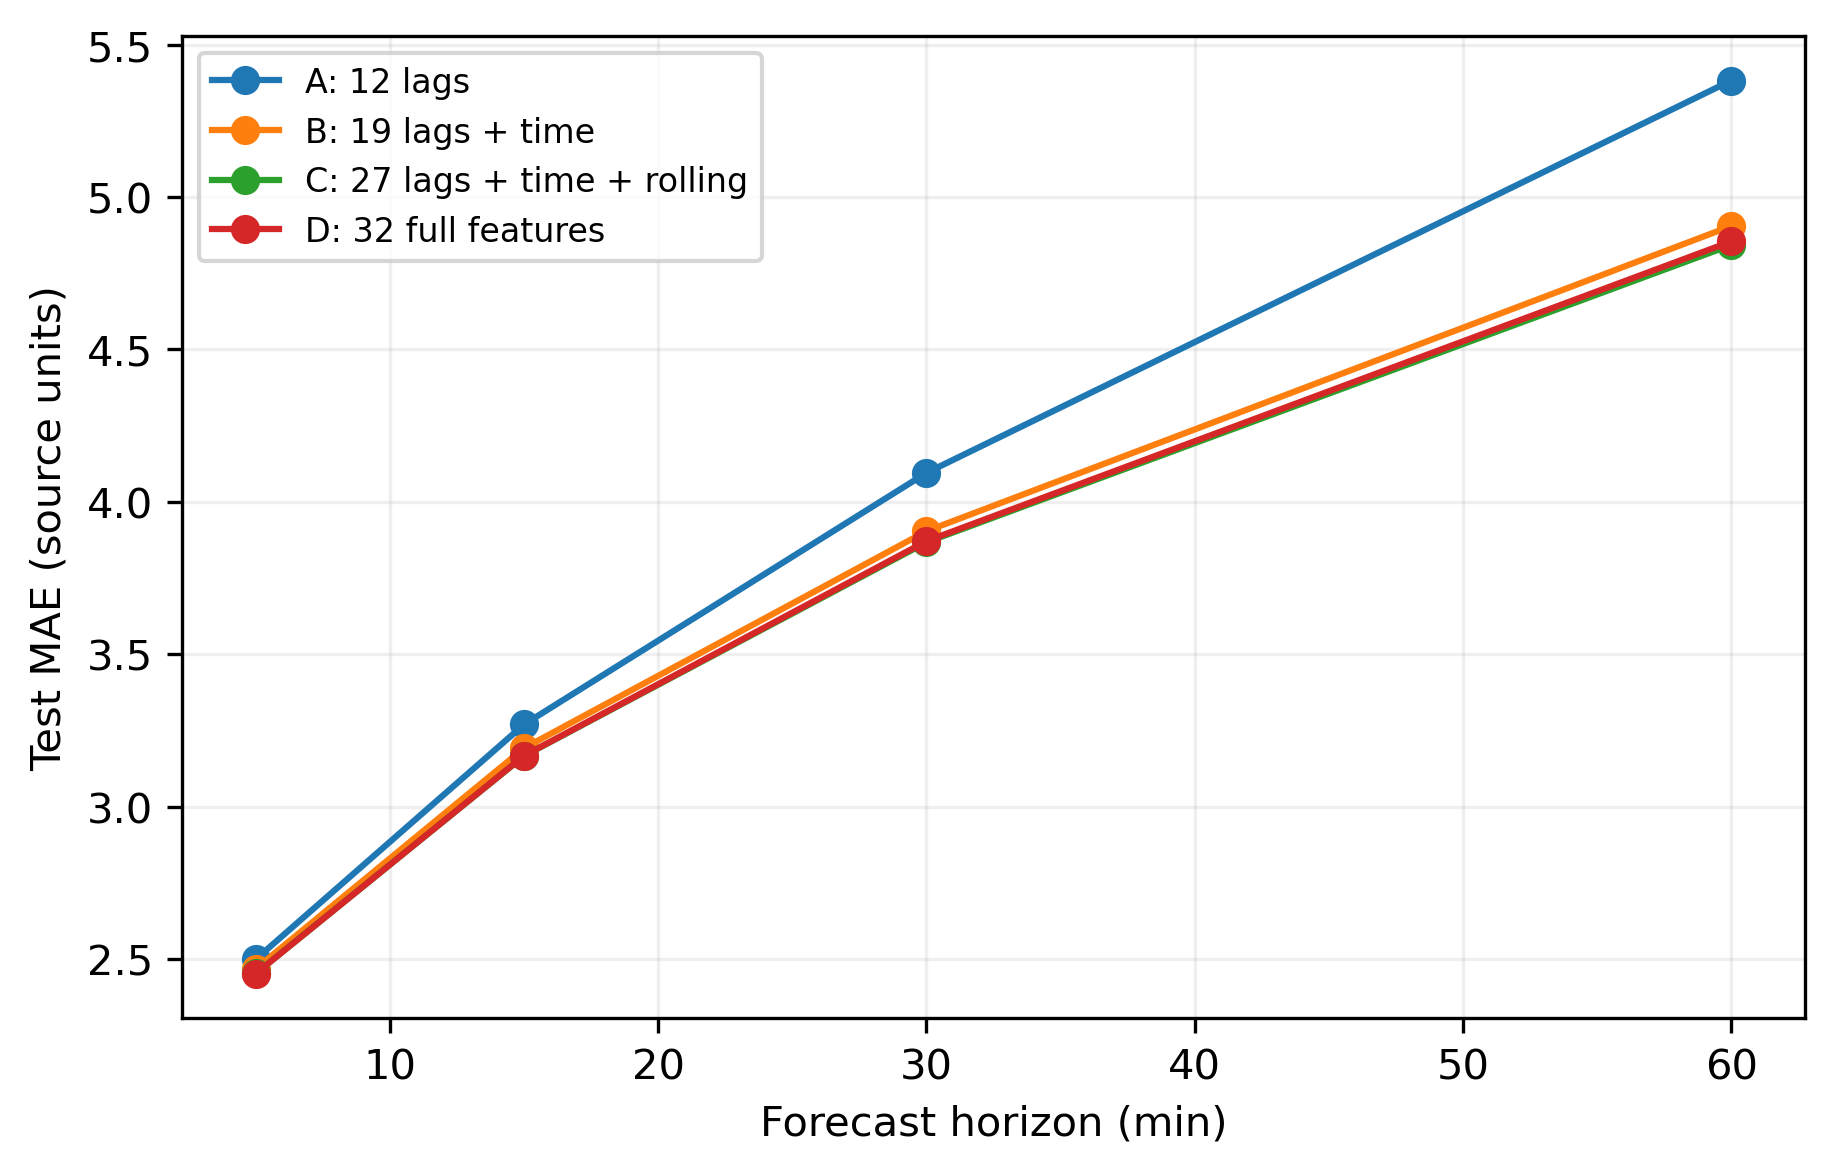

{'sensor_id': '717468',
 'center_target_time': '2012-06-11 19:40:00',
 'selection': 'largest-error event at highest-MAE XGBoost+HA sensor; retrospective test diagnostic only'}

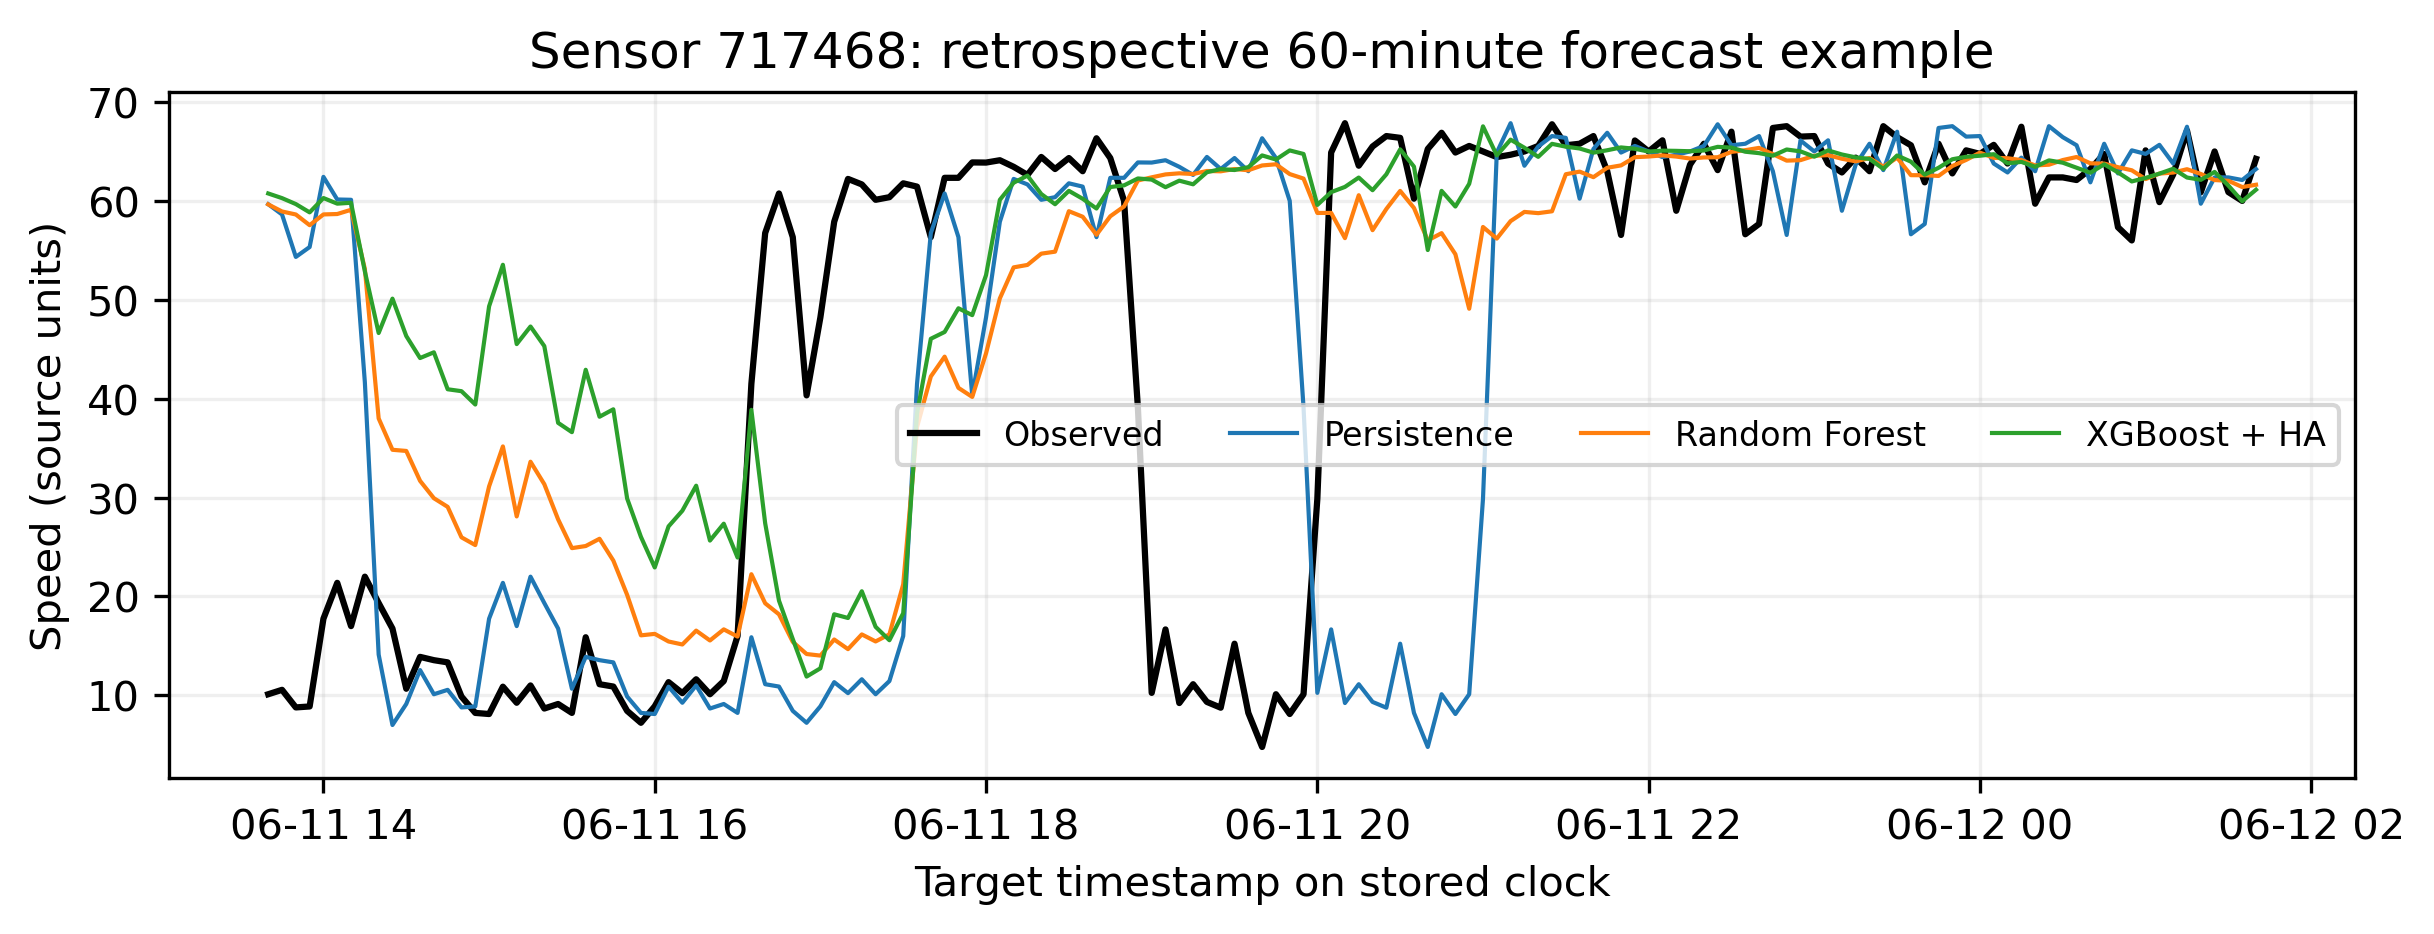

In [8]:
display(Image(filename=str(ROOT/'figures/person_e_rf_ablation_progression.png')))
display(results['example'])
display(Image(filename=str(ROOT/'figures/person_e_prediction_example.png')))

## Reproduction checks and interpretation limits

The input hashes, package versions and model-to-evaluation comparisons are recorded below. Units and timezone are unverified. Missing targets are not imputed. This study does not establish a causal propagation mechanism or a guaranteed improvement from graph learning.

In [9]:
display(pd.DataFrame(results['metric_reproduction_checks']))
print('Hashed inputs:',len(results['input_sha256']))
assert all(r['maximum_metric_difference'] <= .002 for r in results['metric_reproduction_checks'])

,split,horizon,model,maximum_metric_difference
0,val,5min,persistence,0.000034
1,val,5min,historical_average,0.000040
2,val,5min,random_forest_32,0.000037
3,val,5min,xgboost_32,0.000046
4,val,5min,xgboost_ha,0.000044
5,val,15min,persistence,0.000034
6,val,15min,historical_average,0.000037
7,val,15min,random_forest_32,0.000046
8,val,15min,xgboost_32,0.000039
9,val,15min,xgboost_ha,0.000045


Hashed inputs: 66


## Future experiment

A graph model may be compared on the same partitions and observed targets in Phase 2. The existing results motivate this experiment but do not evaluate GAT, DCRNN, or any live traffic control.